# Chapter 04: Shared Outages & Venn Geometry — Python Laboratory
### *Bayesian Common-Cause Diagnosis, Mutual Information, & Reversal Paradox*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/04_mutual_information_and_venn_geometry.ipynb) | [Prev: Ch 03: Where Fleet Priors Come From (Python)](03_maximum_entropy_priors.ipynb) | [Next: Ch 05: The Geometry of Inference (Python)](05_curvature_laplace_and_fisher_information.ipynb)**

---

## 1. Environment Setup

We import scientific libraries and configure visual styles for Information
Venn geometry and Bayesian causal network analysis.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print("Environment initialized with NumPy and Matplotlib.")


Environment initialized with NumPy and Matplotlib.


---

## 2. Implementation: The 2-Variable Information Toolkit

We implement robust functions that take a 2D joint probability matrix $P(X, Y)$
and compute all components of the Information Venn diagram:
1. **Marginal Entropies**: $H(X)$ and $H(Y)$
2. **Joint Entropy**: $H(X, Y)$
3. **Mutual Information**: $I(X; Y) = H(X) + H(Y) - H(X, Y)$
4. **Conditional Entropies**: $H(X \mid Y)$ and $H(Y \mid X)$
5. **Variation of Information**: $VI(X; Y) = H(X \mid Y) + H(Y \mid X)$


In [2]:
def joint_entropy(p_xy):
    # Compute joint Shannon entropy H(X, Y) in bits
    p_xy = np.asarray(p_xy, dtype=np.float64) / np.sum(p_xy)
    mask = p_xy > 1e-15
    return -float(np.sum(p_xy[mask] * np.log2(p_xy[mask])))

def marginal_entropy(p):
    # Compute 1D Shannon entropy H(X) in bits
    p = np.asarray(p, dtype=np.float64) / np.sum(p)
    mask = p > 1e-15
    return -float(np.sum(p[mask] * np.log2(p[mask])))

def mutual_information(p_xy):
    # Compute Mutual Information I(X; Y) in bits
    p_xy = np.asarray(p_xy, dtype=np.float64) / np.sum(p_xy)
    px = np.sum(p_xy, axis=1)
    py = np.sum(p_xy, axis=0)
    hx = marginal_entropy(px)
    hy = marginal_entropy(py)
    hxy = joint_entropy(p_xy)
    return max(0.0, float(hx + hy - hxy))

def conditional_entropy(p_xy, given_axis=1):
    # Compute conditional entropy H(X|Y) or H(Y|X) in bits
    hxy = joint_entropy(p_xy)
    if given_axis == 1:
        # Given Y: H(X|Y) = H(X, Y) - H(Y)
        py = np.sum(p_xy, axis=0)
        return max(0.0, float(hxy - marginal_entropy(py)))
    else:
        # Given X: H(Y|X) = H(X, Y) - H(X)
        px = np.sum(p_xy, axis=1)
        return max(0.0, float(hxy - marginal_entropy(px)))

def variation_of_information(p_xy):
    # Compute Variation of Information VI(X; Y) in bits
    h_x_given_y = conditional_entropy(p_xy, given_axis=1)
    h_y_given_x = conditional_entropy(p_xy, given_axis=0)
    return float(h_x_given_y + h_y_given_x)

print("Information toolkit defined successfully.")


Information toolkit defined successfully.


---

## 3. Bayesian Common-Cause Diagnosis & Information Venn Geometry

We model the **2:15 PM Double Failure** as a 3-node Bayesian causal network
($T_1 \leftarrow Z \to T_2$):
* $Z \in \{0, 1\}$: Hidden infrastructure health ($0 = \text{Healthy}$,
  $1 = \text{Degraded Outage}$). Prior $P(Z = 1) = 0.02$.
* $T_1 \in \{0, 1\}$: Auth test ($0 = \text{Pass}$, $1 = \text{Fail}$).
* $T_2 \in \{0, 1\}$: Billing test ($0 = \text{Pass}$, $1 = \text{Fail}$).

Failure probabilities:
* Healthy ($Z = 0$): $P(T_i = 1 \mid Z = 0) = 0.01$ (independent flakes).
* Degraded ($Z = 1$): $P(T_i = 1 \mid Z = 1) = 0.80$ (simultaneous failures).

We compute the exact Bayesian posterior outage probabilities and map them
directly to the Information Venn partition.


In [3]:
# Physical causal parameters
p_z1 = 0.02
p_z0 = 1.0 - p_z1

p_t_given_z0 = 0.01
p_t_given_z1 = 0.80

# Construct 3D joint distribution P(T1, T2, Z)
# Axis 0: T1, Axis 1: T2, Axis 2: Z
p_t1_t2_z = np.zeros((2, 2, 2))
for z, pz in [(0, p_z0), (1, p_z1)]:
    p_fail = p_t_given_z1 if z == 1 else p_t_given_z0
    for t1 in [0, 1]:
        p1 = p_fail if t1 == 1 else (1.0 - p_fail)
        for t2 in [0, 1]:
            p2 = p_fail if t2 == 1 else (1.0 - p_fail)
            p_t1_t2_z[t1, t2, z] = pz * p1 * p2

# Marginal joint distribution P(T1, T2) by summing over Z
p_t1_t2 = np.sum(p_t1_t2_z, axis=2)

# Step 1: Bayesian Posterior Calculation
p_double_fail = p_t1_t2[1, 1]
p_z1_given_double_fail = p_t1_t2_z[1, 1, 1] / p_double_fail

p_t1 = np.sum(p_t1_t2, axis=1)
p_t2 = np.sum(p_t1_t2, axis=0)
p_single_fail = p_t1[1]
p_z1_given_single_fail = (p_z1 * p_t_given_z1) / p_single_fail

# Step 2: Information-Theoretic Venn Quantities
h_t1 = marginal_entropy(p_t1)
h_t2 = marginal_entropy(p_t2)
h_joint = joint_entropy(p_t1_t2)
mi_t1_t2 = mutual_information(p_t1_t2)
h_t1_given_t2 = conditional_entropy(p_t1_t2, given_axis=1)
h_t2_given_t1 = conditional_entropy(p_t1_t2, given_axis=0)
vi_t1_t2 = variation_of_information(p_t1_t2)

print("=" * 72)
print("             BAYESIAN COMMON-CAUSE OUTAGE DIAGNOSIS")
print("=" * 72)
print(f"Prior Infrastructure Outage Rate P(Z=1):           {p_z1 * 100:.2f}%")
print(f"Marginal Single Failure Rate P(T1=1):              {p_single_fail * 100:.4f}%")
print(f"Marginal Double Failure Rate P(T1=1, T2=1):        {p_double_fail * 100:.4f}%")
print("-" * 72)
print(f"Posterior Outage Given Single Failure P(Z=1|T1=1): {p_z1_given_single_fail * 100:.2f}%")
print(f"Posterior Outage Given Double Failure P(Z=1|T1,T2):{p_z1_given_double_fail * 100:.2f}%")
print("=" * 72)
print("              INFORMATION VENN DIAGRAM PARTITION")
print("=" * 72)
print(f"Marginal Auth Uncertainty H(T1):                  {h_t1:.4f} bits")
print(f"Marginal Billing Uncertainty H(T2):               {h_t2:.4f} bits")
print(f"Joint Union Uncertainty H(T1, T2):                 {h_joint:.4f} bits")
print(f"Mutual Information (Shared Signal) I(T1; T2):      {mi_t1_t2:.4f} bits")
print(f"Residual Auth Uncertainty H(T1 | T2):              {h_t1_given_t2:.4f} bits")
print(f"Residual Billing Uncertainty H(T2 | T1):           {h_t2_given_t1:.4f} bits")
print(f"Variation of Information VI(T1; T2):               {vi_t1_t2:.4f} bits")
print("=" * 72)


             BAYESIAN COMMON-CAUSE OUTAGE DIAGNOSIS
Prior Infrastructure Outage Rate P(Z=1):           2.00%
Marginal Single Failure Rate P(T1=1):              2.5800%
Marginal Double Failure Rate P(T1=1, T2=1):        1.2898%
------------------------------------------------------------------------
Posterior Outage Given Single Failure P(Z=1|T1=1): 62.02%
Posterior Outage Given Double Failure P(Z=1|T1,T2):99.24%
              INFORMATION VENN DIAGRAM PARTITION
Marginal Auth Uncertainty H(T1):                  0.1729 bits
Marginal Billing Uncertainty H(T2):               0.1729 bits
Joint Union Uncertainty H(T1, T2):                 0.2977 bits
Mutual Information (Shared Signal) I(T1; T2):      0.0481 bits
Residual Auth Uncertainty H(T1 | T2):              0.1248 bits
Residual Billing Uncertainty H(T2 | T1):           0.1248 bits
Variation of Information VI(T1; T2):               0.2496 bits


---

## 4. Simulating the Reversal Paradox: Fork vs. Collider

We simulate two fundamental causal topologies:
1. **The Fork ($T_1 \leftarrow Z \to T_2$)**: Shared Redis cache $Z$ creates
   positive mutual information ($I(T_1; T_2) > 0$). Conditioning on $Z$
   destroys it completely: $I(T_1; T_2 \mid Z) = 0.0000\text{ bits}$.
   Interaction information is positive (Redundancy).
2. **The Collider ($X \to Z \leftarrow Y$)**: Independent failure sources
   ($I(X; Y) = 0.0000\text{ bits}$). Conditioning on a shared queue alert
   ($Z = X \lor Y$) creates mutual information out of thin air:
   $I(X; Y \mid Z) > 0$. Interaction information is negative (Synergy).


In [4]:
# 1. THE FORK (Confounder: T1 <-- Z --> T2)
mi_fork_uncond = mutual_information(p_t1_t2)

# Conditional MI: sum_z P(z) * I(T1; T2 | z)
mi_fork_cond = 0.0
for z in [0, 1]:
    pz = np.sum(p_t1_t2_z[:, :, z])
    p_t1_t2_given_z = p_t1_t2_z[:, :, z] / pz
    mi_fork_cond += pz * mutual_information(p_t1_t2_given_z)

# 2. THE COLLIDER (OR Gate / Berkson's Bias: X --> Z <-- Y)
# X = Payment timeout (50/50), Y = Email crash (50/50), independent
p_xyz_collider = np.zeros((2, 2, 2))
for x in [0, 1]:
    for y in [0, 1]:
        z = x | y
        p_xyz_collider[x, y, z] = 0.25

p_xy_collider = np.sum(p_xyz_collider, axis=2)
mi_coll_uncond = mutual_information(p_xy_collider)

mi_coll_cond = 0.0
for z in [0, 1]:
    pz = np.sum(p_xyz_collider[:, :, z])
    if pz > 0:
        p_xy_given_z = p_xyz_collider[:, :, z] / pz
        mi_coll_cond += pz * mutual_information(p_xy_given_z)

print("=" * 72)
print("                     THE REVERSAL PARADOX")
print("=" * 72)
print("1. THE FORK (Shared Outage Confounder: T1 <-- Z --> T2):")
print(f"   Unconditional I(T1; T2):     {mi_fork_uncond:.4f} bits (Spurious correlation)")
print(f"   Conditioned I(T1; T2 | Z):   {mi_fork_cond:.4f} bits (Redis explains it away!)")
print(f"   Interaction Information:    +{mi_fork_uncond - mi_fork_cond:.4f} bits (Redundancy > 0)")
print("-" * 72)
print("2. THE COLLIDER (Shared Queue Alert: X --> Z <-- Y):")
print(f"   Unconditional I(X; Y):       {mi_coll_uncond:.4f} bits (Strictly independent)")
print(f"   Conditioned I(X; Y | Z):     {mi_coll_cond:.4f} bits (Conditioning creates bits!)")
print(f"   Interaction Information:     {mi_coll_uncond - mi_coll_cond:.4f} bits (Synergy < 0)")
print("=" * 72)


                     THE REVERSAL PARADOX
1. THE FORK (Shared Outage Confounder: T1 <-- Z --> T2):
   Unconditional I(T1; T2):     0.0481 bits (Spurious correlation)
   Conditioned I(T1; T2 | Z):   0.0000 bits (Redis explains it away!)
   Interaction Information:    +0.0481 bits (Redundancy > 0)
------------------------------------------------------------------------
2. THE COLLIDER (Shared Queue Alert: X --> Z <-- Y):
   Unconditional I(X; Y):       0.0000 bits (Strictly independent)
   Conditioned I(X; Y | Z):     0.1887 bits (Conditioning creates bits!)
   Interaction Information:     -0.1887 bits (Synergy < 0)


---

## 5. Visualizing the Information Venn Diagram & The Paradox

We generate a comprehensive 3-panel figure:
* **Panel 1**: The geometric Information Venn Diagram with exact partitions.
* **Panel 2**: The Reversal Paradox bar chart comparing Fork vs. Collider.
* **Panel 3**: Bayesian Outage Probability escalation from Prior to Double Fail.


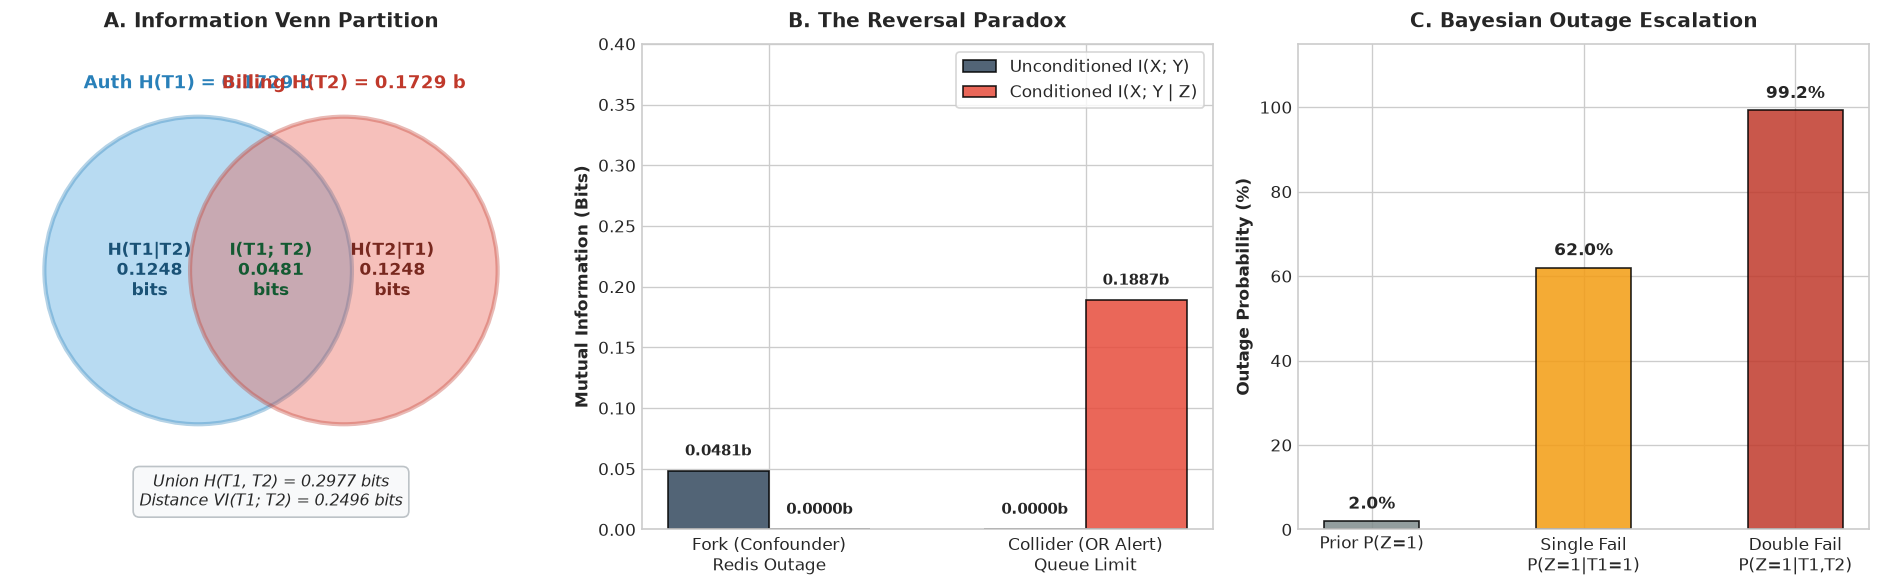

In [5]:
# 1 row, 3 columns of subplots for Venn geometry, conditional MI, and DAGs
fig, axes = plt.subplots(1, 3, figsize=(16, 5.0))

# Panel 1: Information Venn Diagram
ax = axes[0]
circle_x = Circle((-0.45, 0), 0.95, facecolor='#3498db', alpha=0.35, edgecolor='#2980b9', lw=2.5)
circle_y = Circle((0.45, 0), 0.95, facecolor='#e74c3c', alpha=0.35, edgecolor='#c0392b', lw=2.5)
ax.add_patch(circle_x)
ax.add_patch(circle_y)

ax.text(-0.75, 0.0, f"H(T1|T2)\n{h_t1_given_t2:.4f}\nbits", ha='center', va='center',
        fontsize=10, fontweight='bold', color='#1a5276')
ax.text(0.75, 0.0, f"H(T2|T1)\n{h_t2_given_t1:.4f}\nbits", ha='center', va='center',
        fontsize=10, fontweight='bold', color='#78281f')
ax.text(0.0, 0.0, f"I(T1; T2)\n{mi_t1_t2:.4f}\nbits", ha='center', va='center',
        fontsize=10, fontweight='bold', color='#145a32')

ax.text(-0.45, 1.10, f"Auth H(T1) = {h_t1:.4f} b", ha='center', va='bottom',
        fontsize=10.5, fontweight='bold', color='#2980b9')
ax.text(0.45, 1.10, f"Billing H(T2) = {h_t2:.4f} b", ha='center', va='bottom',
        fontsize=10.5, fontweight='bold', color='#c0392b')
ax.text(0.0, -1.25, f"Union H(T1, T2) = {h_joint:.4f} bits\nDistance VI(T1; T2) = {vi_t1_t2:.4f} bits",
        ha='center', va='top', fontsize=9.5, style='italic',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#f8f9fa', edgecolor='#bdc3c7'))

ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.6, 1.4)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title("A. Information Venn Partition", fontsize=12, fontweight='bold', pad=10)

# Panel 2: The Reversal Paradox Bar Chart
labels = ['Fork (Confounder)\nRedis Outage', 'Collider (OR Alert)\nQueue Limit']
x_pos = np.arange(len(labels))
width = 0.32

rects1 = axes[1].bar(x_pos - width/2, [mi_fork_uncond, mi_coll_uncond], width,
                     label='Unconditioned I(X; Y)', color='#34495e', alpha=0.85, edgecolor='black')
rects2 = axes[1].bar(x_pos + width/2, [mi_fork_cond, mi_coll_cond], width,
                     label='Conditioned I(X; Y | Z)', color='#e74c3c', alpha=0.85, edgecolor='black')

for rect in rects1:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2.0, h + 0.010, f"{h:.4f}b",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2.0, h + 0.010, f"{h:.4f}b",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels, fontsize=10)
axes[1].set_ylim(0, 0.40)
axes[1].set_ylabel("Mutual Information (Bits)", fontsize=10, fontweight='bold')
axes[1].set_title("B. The Reversal Paradox", fontsize=12, fontweight='bold', pad=10)
axes[1].legend(loc='upper right', frameon=True)

# Panel 3: Bayesian Outage Probability Escalation
stages = ['Prior P(Z=1)', 'Single Fail\nP(Z=1|T1=1)', 'Double Fail\nP(Z=1|T1,T2)']
probs = [p_z1 * 100, p_z1_given_single_fail * 100, p_z1_given_double_fail * 100]
colors = ['#7f8c8d', '#f39c12', '#c0392b']

bars = axes[2].bar(stages, probs, color=colors, alpha=0.85, edgecolor='black', width=0.45)
for bar in bars:
    y = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2.0, y + 2.0, f"{y:.1f}%",
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

axes[2].set_ylim(0, 115)
axes[2].set_ylabel("Outage Probability (%)", fontsize=10, fontweight='bold')
axes[2].set_title("C. Bayesian Outage Escalation", fontsize=12, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()


---

## 6. 3-Tier Exercises & Explorations

### Tier 1: Warmup — The Independent Sensor
Suppose two test runs are completely independent fair coin flips:
$$P(X=0, Y=0) = P(X=0, Y=1) = P(X=1, Y=0) = P(X=1, Y=1) = 0.25$$
Verify that:
* $H(X) = 1.0\text{ bit}$
* $H(Y) = 1.0\text{ bit}$
* $I(X; Y) = 0.0\text{ bits}$
* $VI(X; Y) = 2.0\text{ bits}$

### Tier 2: Intermediate — Symmetric vs. Asymmetric Flakes
Suppose the baseline flake rate of Test 2 increases from $0.01$ to $0.05$.
How does the marginal mutual information $I(T_1; T_2)$ and the posterior
probability $P(Z = 1 \mid T_1 = 1, T_2 = 1)$ shift?

### Tier 3: Advanced — Sizing Outage Thresholds via Bayes & Information Gain
Using your information toolkit, calculate the mutual information between
infrastructure state $Z$ and the test vector $(T_1, T_2)$:
$$I(T_1, T_2; Z) = H(T_1, T_2) - H(T_1, T_2 \mid Z)$$
Verify that observing both tests resolves the vast majority of infrastructure
uncertainty.


In [6]:
# Solution verification for Tier 1:
p_indep = np.full((2, 2), 0.25)
print("Tier 1 Solutions (Independent fair tests):")
print(f"H(X):            {marginal_entropy(np.sum(p_indep, axis=1)):.4f} bits")
print(f"H(Y):            {marginal_entropy(np.sum(p_indep, axis=0)):.4f} bits")
print(f"H(X, Y):         {joint_entropy(p_indep):.4f} bits")
print(f"I(X; Y):         {mutual_information(p_indep):.4f} bits")
print(f"VI(X; Y):        {variation_of_information(p_indep):.4f} bits")

# Tier 3 Solution Verification:
h_t1_t2_given_z = 0.0
for z, pz in [(0, p_z0), (1, p_z1)]:
    p_given_z = p_t1_t2_z[:, :, z] / pz
    h_t1_t2_given_z += pz * joint_entropy(p_given_z)

i_tests_infra = h_joint - h_t1_t2_given_z
h_z = marginal_entropy([p_z0, p_z1])
print("\nTier 3 Solutions (Infrastructure Information):")
print(f"Prior Infrastructure Entropy H(Z):   {h_z:.4f} bits")
print(f"Conditional Entropy H(T1, T2 | Z):   {h_t1_t2_given_z:.4f} bits")
print(f"Mutual Information I(T1, T2; Z):     {i_tests_infra:.4f} bits")
print(f"Fraction of Outage Entropy Resolved: {i_tests_infra / h_z * 100:.2f}%")


Tier 1 Solutions (Independent fair tests):
H(X):            1.0000 bits
H(Y):            1.0000 bits
H(X, Y):         2.0000 bits
I(X; Y):         0.0000 bits
VI(X; Y):        2.0000 bits

Tier 3 Solutions (Infrastructure Information):
Prior Infrastructure Entropy H(Z):   0.1414 bits
Conditional Entropy H(T1, T2 | Z):   0.1872 bits
Mutual Information I(T1, T2; Z):     0.1104 bits
Fraction of Outage Entropy Resolved: 78.07%


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/04_mutual_information_and_venn_geometry.ipynb) | [Prev: Ch 03: Where Fleet Priors Come From (Python)](03_maximum_entropy_priors.ipynb) | [Next: Ch 05: The Geometry of Inference (Python)](05_curvature_laplace_and_fisher_information.ipynb)**
